# Student Academic Performance Prediction using a Deep Neural Network

**Goal:** predict whether a student will **PASS** (final grade G3 ≥ 10 out of 20) or is **AT RISK** of failing (G3 < 10).

**Data:** UCI Student Performance dataset, Portuguese course: 649 students, 33 columns (P. Cortez and A. Silva, 2008, CC BY 4.0, https://archive.ics.uci.edu/dataset/320/student+performance).
On Kaggle the notebook reads the attached dataset `uciml/student-alcohol-consumption`, an exact copy of the UCI file.

**Plan of this notebook**

| Step | What |
|---|---|
| 1 | Setup |
| 2 | The data: what columns there are |
| 3 | Looking at the data (EDA) |
| 4 | Target and train/test split |
| 5 | Preparing the inputs: encoding, scaling, choosing columns |
| 6 | The neural network |
| 7 | How every setting was chosen |
| 8 | Training the final network |
| 9 | Results on the test students |
| 10 | Comparison with traditional machine learning |
| 11 | Why these inputs and not the others |
| 12 | Predicting individual students |
| 13 | Summary |

## 1. Setup

In [1]:
import os, sys, glob, subprocess, json
os.environ.setdefault("KERAS_BACKEND", "torch")          # Keras runs on top of PyTorch (no TensorFlow needed)

kaggle_csv = glob.glob("/kaggle/input/**/student-por.csv", recursive=True)
if kaggle_csv:                                            # on Kaggle: use the attached copy of the UCI data
    os.environ["STUDENT_DATA_PATH"] = kaggle_csv[0]
if not os.path.exists("src"):                             # on Kaggle: download the project code from GitHub
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/auraCodesKM/student-performance-dnn.git"], check=True)
    os.chdir("student-performance-dnn")
sys.path.insert(0, os.getcwd())

import inspect
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src.data import CATEGORICAL, DESCRIPTIONS, FEATURES, GROUPS, NUMERIC, load_data, make_preprocessor, split
from src.eda import audit, figures
from src.model import build_model, predict_at_risk, train_model
from src.train import scores
%matplotlib inline

## 2. The data: what columns there are

33 columns: 30 about the student, plus the three grades G1 (1st period), G2 (2nd period) and **G3 (final grade, what we predict)**.
So the model has **32 inputs**, in four groups (as the project brief describes them).

In [2]:
df = load_data()
print(df.shape[0], "students,", 33, "columns")
group_of = {c: g for g, cols in GROUPS.items() for c in cols}
pd.DataFrame({"column": FEATURES + ["G3"],
              "meaning": [DESCRIPTIONS[c] for c in FEATURES] + ["Final grade (0-20) - the target"],
              "group": [group_of[c] for c in FEATURES] + ["target"],
              "type": ["number" if c in NUMERIC else "category" for c in FEATURES] + ["number"]})

649 students, 33 columns


,column,meaning,group,type
0,age,Age (15-22),Demographic,number
1,Medu,Mother's education (0-4),Demographic,number
2,Fedu,Father's education (0-4),Demographic,number
3,traveltime,Travel time to school (1-4),Academic,number
4,studytime,Weekly study time (1-4),Academic,number
5,failures,Past class failures (0-3),Academic,number
6,famrel,Family relationship quality (1-5),Social,number
7,freetime,Free time after school (1-5),Social,number
8,goout,Going out with friends (1-5),Social,number
9,Dalc,Workday alcohol use (1-5),Behavioural,number


## 3. Looking at the data (EDA)

What we check, and what we decided because of it:
- **Missing values: 0**, so nothing to fill in.
- **Only 15.4% of students fail.** A model that always says "pass" would already be 84.6% accurate, so we also measure recall and F1.
- **15 students have a final grade of 0, all with 0 absences.** They probably dropped out. They are real fails, so we keep them.
- **G2 is very close to G3** (correlation 0.92), so the period grades will be the strongest inputs.

In [3]:
audit(df)

Shape: (649, 34)
Missing values: 0
Duplicate rows: 0
At-risk (G3 < 10) share: 15.4% -> majority-class accuracy would be 84.6%
G3 == 0: 15 students; with zero absences: 15 (vs 37.6% of all students) -> likely dropped out / missed the final exam
Correlation with G3: {'G1': 0.826, 'G2': 0.919}
'Pass if G2 >= 10' rule accuracy: 89.7%
Absences skew: 2.02 max: 32


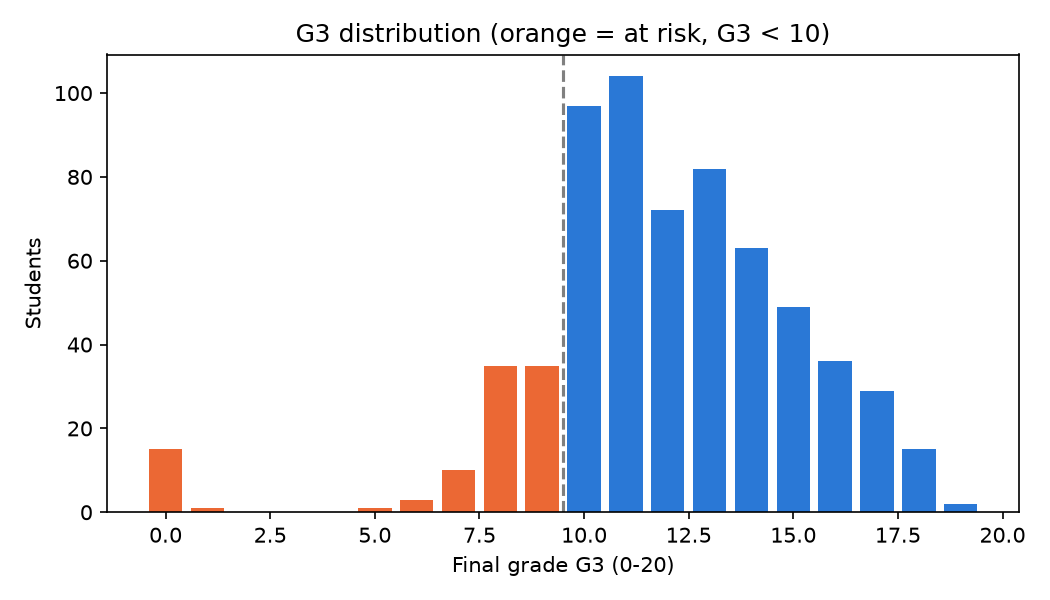

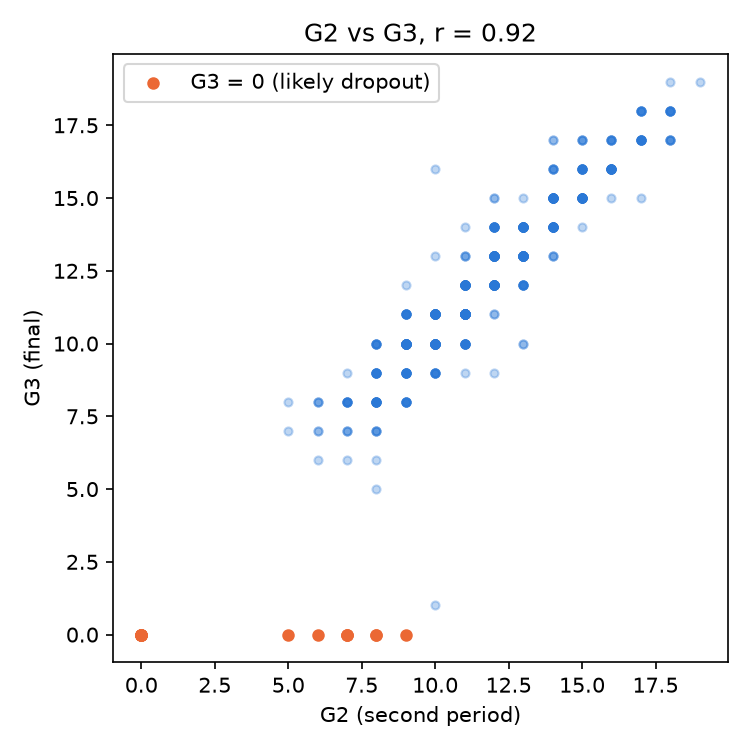

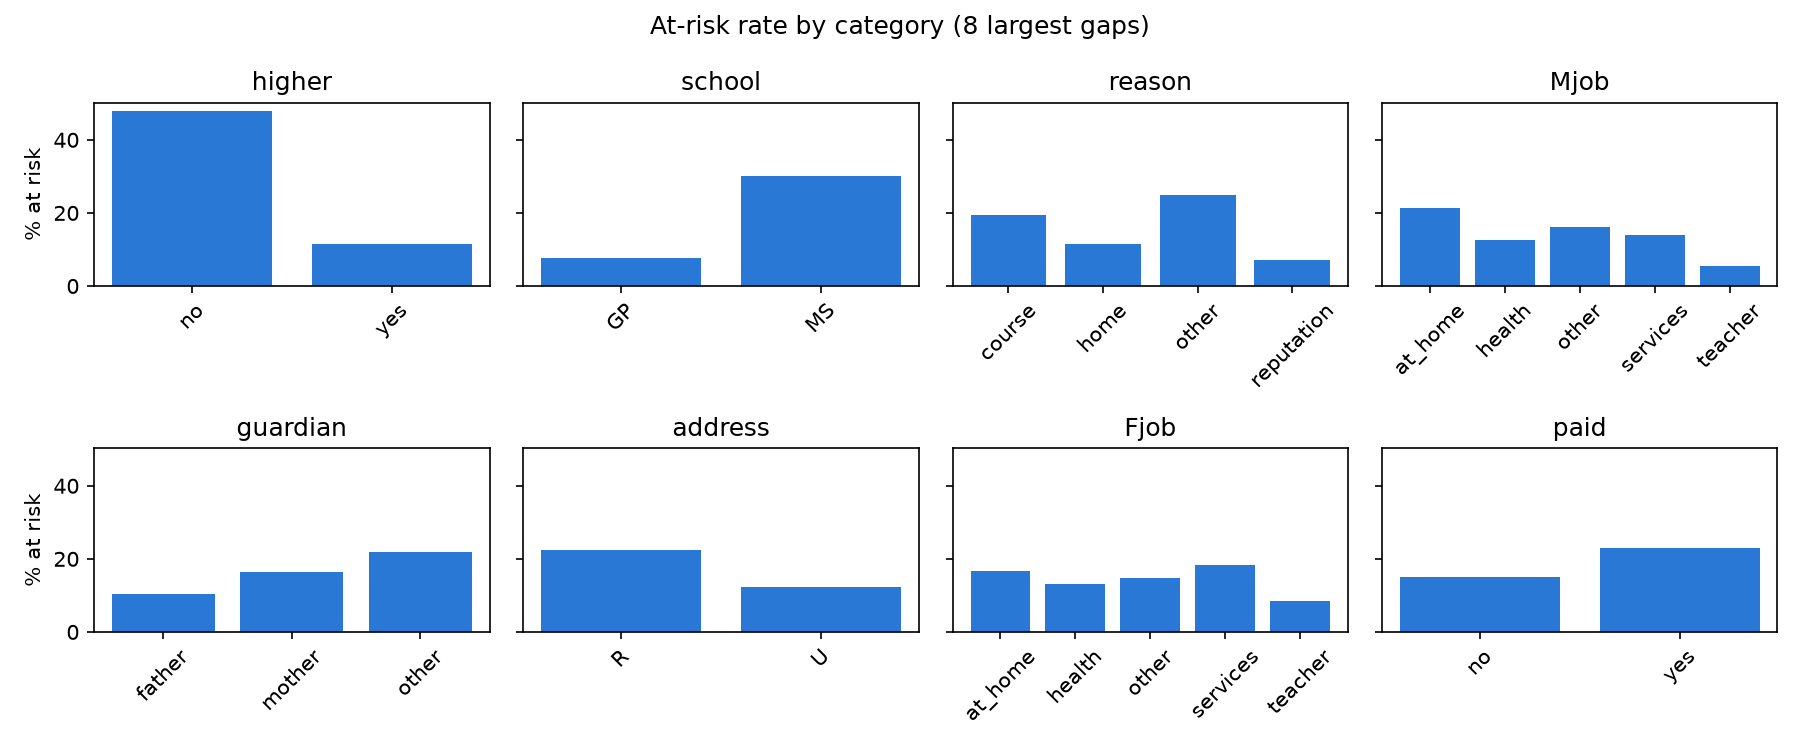

In [4]:
figures(df)
for name in ["g3_distribution", "g2_vs_g3", "risk_by_category"]:
    display(Image(f"results/figures/{name}.png", width=650))

## 4. Target and train/test split

- **Target:** `at_risk = 1` if G3 < 10, else 0.
- **Split:** 80% of students (519) to learn from, and 20% (130) kept aside as the **test set**.
- The test students are used only once, at the end. "Stratified" means both parts keep the same 15% at-risk share.

In [5]:
train, test = split(df)
print("training students:", len(train), "| at risk:", train.at_risk.sum())
print("test students:    ", len(test), "| at risk:", test.at_risk.sum())

training students: 519 | at risk: 80
test students:     130 | at risk: 20


## 5. Preparing the inputs

A neural network needs numbers on similar scales:
1. **One-hot encoding** of text columns. For example, school GP/MS becomes one 0/1 column `school_MS`, and mother's job (5 options) becomes 5 columns.
2. **Standardisation** of number columns: (value − average) ÷ spread, so each column has average 0. The averages come from the training students only.
3. **Choosing columns:** each column gets an **information score** (mutual information: how much it tells us about pass / at risk). We keep the top ones; section 7 shows how many.

All three steps are learned from the training students only, so the test students cannot leak into the model.

In [6]:
report = json.load(open("results/results.json"))
k = report["k"]
prep = make_preprocessor(k).fit(train, train.at_risk)
print("32 inputs -> 45 columns after one-hot encoding -> kept", k, ":", list(prep.named_steps["select"].get_feature_names_out()))
example = test.iloc[[0]]
display(example[FEATURES])
print("the same student as the network sees it:")
display(prep.transform(example).round(3))

32 inputs -> 45 columns after one-hot encoding -> kept 5 : ['school_MS', 'higher_yes', 'failures', 'G1', 'G2']


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
21,15,4,4,1,1,0,5,4,2,1,...,other,father,no,yes,yes,no,yes,yes,yes,no


the same student as the network sees it:


array([[ 0.   ,  1.   , -0.384, -0.166,  0.156]])

## 6. The neural network

A **Keras Sequential** model:
- **Input:** the selected columns.
- **Hidden layers:** `Dense` layers of neurons, each followed by **Dropout**, which randomly switches off neurons while training so the network can't memorise the training students.
- **Output:** one neuron with **sigmoid**, which gives a probability between 0 and 1. AT RISK if it is 0.5 or more.
- **Loss:** binary cross-entropy, the standard loss for yes/no predictions.
- **Training:** the optimizer updates the weights batch by batch (32 students at a time). **Early stopping** stops when the validation loss hasn't improved for 20 epochs and keeps the best weights.

In [7]:
print(inspect.getsource(build_model)); print(inspect.getsource(train_model))

def build_model(n_inputs, hidden=(16, 8), dropout=0.3, learning_rate=0.001, activation="relu", optimizer="adam"):
    """inputs -> hidden layers (each: Dense + Dropout) -> 1 output with sigmoid = probability of being at risk."""
    keras.utils.set_random_seed(42)  # same starting weights every time, so results are repeatable
    model = keras.Sequential([keras.Input(shape=(n_inputs,))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation, kernel_initializer="he_normal"))
        model.add(layers.Dropout(dropout))  # randomly switches off neurons while training, to avoid overfitting
    model.add(layers.Dense(1, activation="sigmoid"))  # output between 0 and 1
    if optimizer == "adam":
        opt = keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        opt = keras.optimizers.SGD(learning_rate=learning_rate)
    model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    return model

def train_model(model, X, y):


In [8]:
s = report["settings"]
net = build_model(k, hidden=tuple(s["hidden"]), dropout=s["dropout"], learning_rate=s["learning_rate"],
                  activation=s["activation"], optimizer=s["optimizer"])
net.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

## 7. How every setting was chosen

Every choice was tested with **5-fold cross-validation on the training students**: train on 4/5 of them, check on the other 1/5, five times, then average.
We compare by **F1**, because it rewards actually finding the at-risk students.

- **A. How many columns to keep:** 5, 10, 20 or all 45.
- **B. Grid search:** 2 layer sizes × 2 dropout rates × 2 learning rates = 8 combinations.
- **C. Activation:** ReLU vs tanh vs sigmoid.
- **D. Optimizer:** Adam vs SGD.

These experiments train about 85 networks (about 25 minutes), so the saved results are shown here. Set `RUN_EXPERIMENTS = True` to redo them.

A. Columns kept


,accuracy,precision,recall,f1
5,0.910,0.717,0.725,0.711
10,0.919,0.792,0.638,0.700
20,0.894,0.684,0.638,0.656
all,0.896,0.700,0.600,0.643


B. Grid search


,accuracy,precision,recall,f1
16-8 | dropout 0.4 | lr 0.01,0.925,0.755,0.812,0.767
32-16 | dropout 0.4 | lr 0.01,0.919,0.766,0.738,0.738
32-16 | dropout 0.2 | lr 0.01,0.913,0.761,0.738,0.732
16-8 | dropout 0.2 | lr 0.01,0.910,0.697,0.750,0.715
32-16 | dropout 0.2 | lr 0.001,0.912,0.727,0.712,0.714
16-8 | dropout 0.4 | lr 0.001,0.908,0.703,0.700,0.696
16-8 | dropout 0.2 | lr 0.001,0.900,0.686,0.712,0.688
32-16 | dropout 0.4 | lr 0.001,0.904,0.710,0.662,0.681


C. Activation


,accuracy,precision,recall,f1
relu,0.925,0.755,0.812,0.767
sigmoid,0.929,0.786,0.762,0.762
tanh,0.906,0.732,0.662,0.684


D. Optimizer


,accuracy,precision,recall,f1
adam,0.925,0.755,0.812,0.767
sgd,0.915,0.811,0.588,0.679


chosen: 5 columns, {'hidden': [16, 8], 'dropout': 0.4, 'learning_rate': 0.01, 'activation': 'relu', 'optimizer': 'adam'}


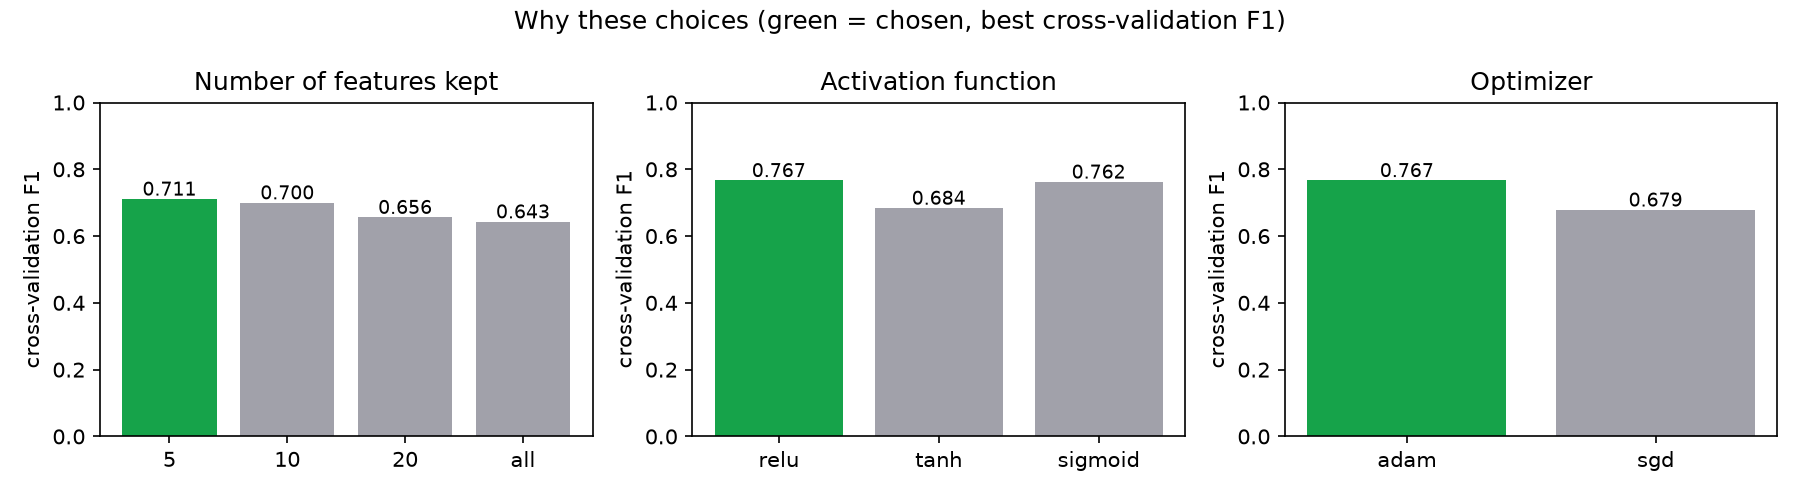

In [9]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    from src import train as T; T.main(); report = json.load(open("results/results.json"))
exp = report["experiments"]
for name, title in [("features", "A. Columns kept"), ("grid", "B. Grid search"), ("activation", "C. Activation"), ("optimizer", "D. Optimizer")]:
    print(title); display(pd.DataFrame(exp[name]).T.round(3).sort_values("f1", ascending=False))
print("chosen:", report["k"], "columns,", report["settings"])
display(Image("results/figures/choices.png", width=950))

## 8. Training the final network

Now we train once more on **all 519 training students** with the chosen settings. Training takes a few seconds.

trained 56 epochs; best epoch 36


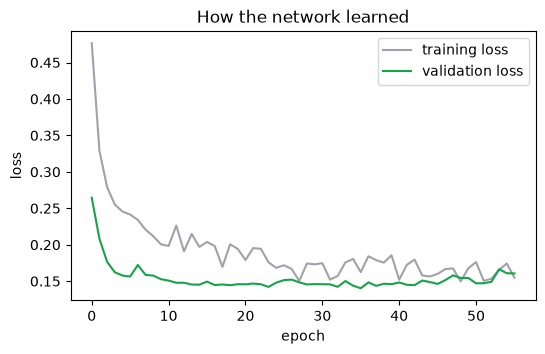

In [10]:
X_train, X_test = prep.transform(train), prep.transform(test)
history = train_model(net, X_train, train.at_risk.to_numpy())
print("trained", len(history.history["loss"]), "epochs; best epoch", int(np.argmin(history.history["val_loss"])) + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(history.history["loss"], color="#a1a1aa", label="training loss")
plt.plot(history.history["val_loss"], color="#16a34a", label="validation loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("How the network learned"); plt.show()

**Reading the curve:** both losses go down, so the network is learning. When the validation loss stops improving, early stopping ends training and keeps the best weights.

## 9. Results on the 130 test students

{'accuracy': 0.9307692307692308, 'precision': 0.7894736842105263, 'recall': 0.75, 'f1': 0.7692307692307693}
              precision    recall  f1-score   support

        Pass      0.955     0.964     0.959       110
     At risk      0.789     0.750     0.769        20

    accuracy                          0.931       130
   macro avg      0.872     0.857     0.864       130
weighted avg      0.929     0.931     0.930       130



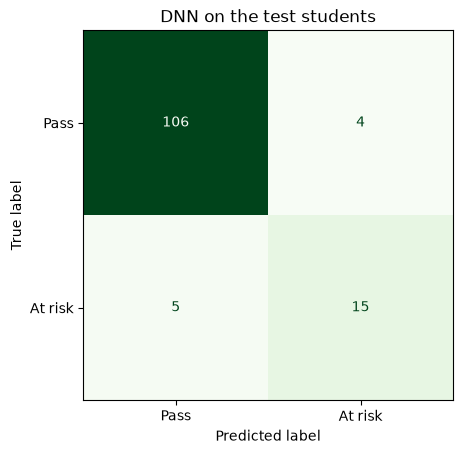

In [11]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
pred = (predict_at_risk(net, X_test) >= 0.5).astype(int)
print(scores(test.at_risk, pred))
print(classification_report(test.at_risk, pred, target_names=["Pass", "At risk"], digits=3))
ConfusionMatrixDisplay.from_predictions(test.at_risk, pred, display_labels=["Pass", "At risk"], cmap="Greens", colorbar=False)
plt.title("DNN on the test students"); plt.show()

**Result on the 130 test students:** 93.1% accuracy (121 of 130 correct).
- 106 passing students correctly predicted PASS, and 15 of the 20 failing students caught.
- 4 false alarms and 5 missed students.
- Precision 78.9%: when it says AT RISK, it is right about 4 times out of 5. Recall 75%: it finds 3 out of 4 failing students.

## 10. Comparison with traditional machine learning

The brief asks for a comparison with at least one traditional model. We used three:
- **Logistic regression:** a weighted sum of the inputs plus a sigmoid. Basically a neural network with no hidden layer.
- **Decision tree:** a series of yes/no questions.
- **Random forest:** 300 decision trees that vote.

Everything else is the same as for the DNN: the same students, the same input columns and the same 5 folds. Each model also got a small grid search of its main setting.

,CV accuracy,CV F1,test accuracy,test precision,test recall,test f1
DNN (neural network),0.925,0.767,0.931,0.789,0.75,0.769
Logistic regression,0.929,0.753,0.923,0.750,0.75,0.750
Decision tree,0.937,0.755,0.938,0.875,0.70,0.778
Random forest,0.929,0.751,0.900,0.640,0.80,0.711
Always predict 'pass',NaN,NaN,0.846,0.000,0.00,0.000


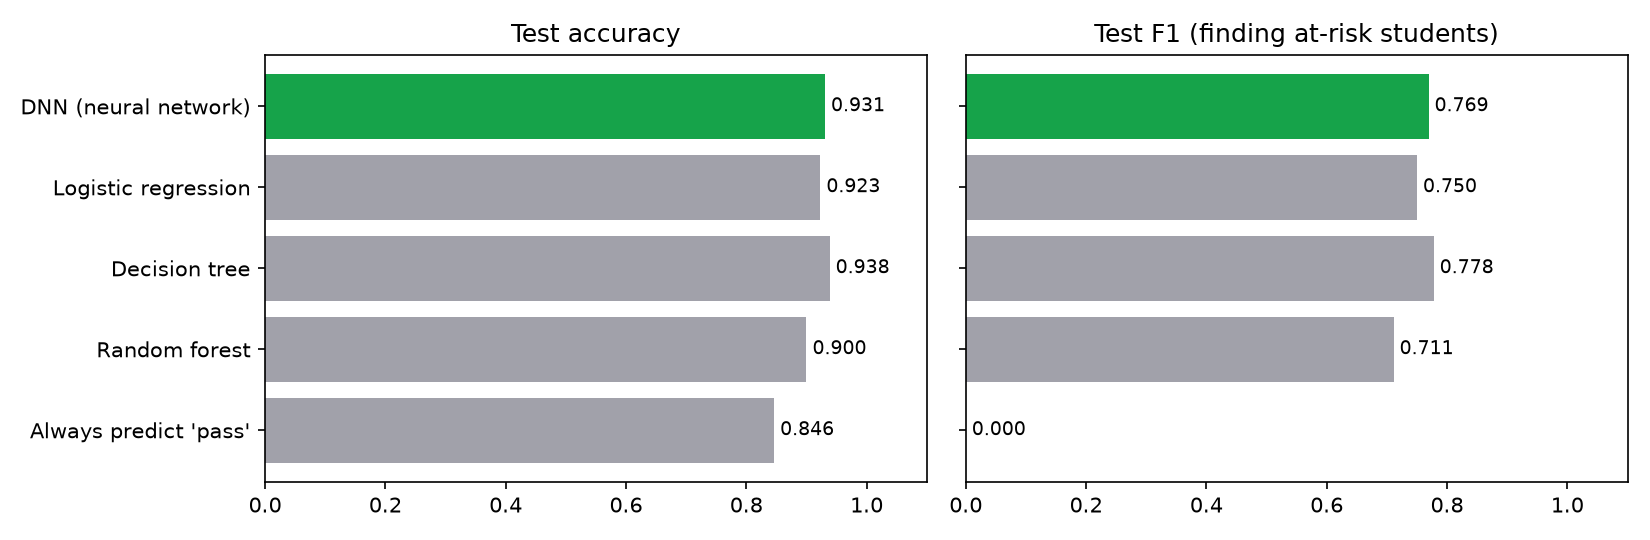

In [12]:
rows = {n: {"CV accuracy": r["cv"]["accuracy"] if r["cv"] else None, "CV F1": r["cv"]["f1"] if r["cv"] else None,
            **{f"test {m}": v for m, v in r["test"].items()}} for n, r in report["models"].items()}
display(pd.DataFrame(rows).T.round(3))
display(Image("results/figures/comparison.png", width=950))

**What the comparison shows**
- **Cross-validation** (the fairest comparison, 5 rounds on the training students): the DNN has the **best F1 (0.767)** and the **best recall (0.812)**, so it finds the most failing students.
- **Test set:** all models are close (90.0–93.8% accuracy). The decision tree is 1 student better than the DNN on accuracy, and random forest is worst.
- With only 130 test students, 1 student is 0.8% of accuracy, so these test differences are small.
- **Conclusion:** the DNN is as good as the best traditional models, and the best at finding at-risk students in cross-validation. With the grades known, this problem is fairly easy, so simple models do well too.

## 11. Why these inputs and not the others

Every column got an information score on the training students, and the top ones were kept (section 7A).
The graph shows the 20 highest scores.

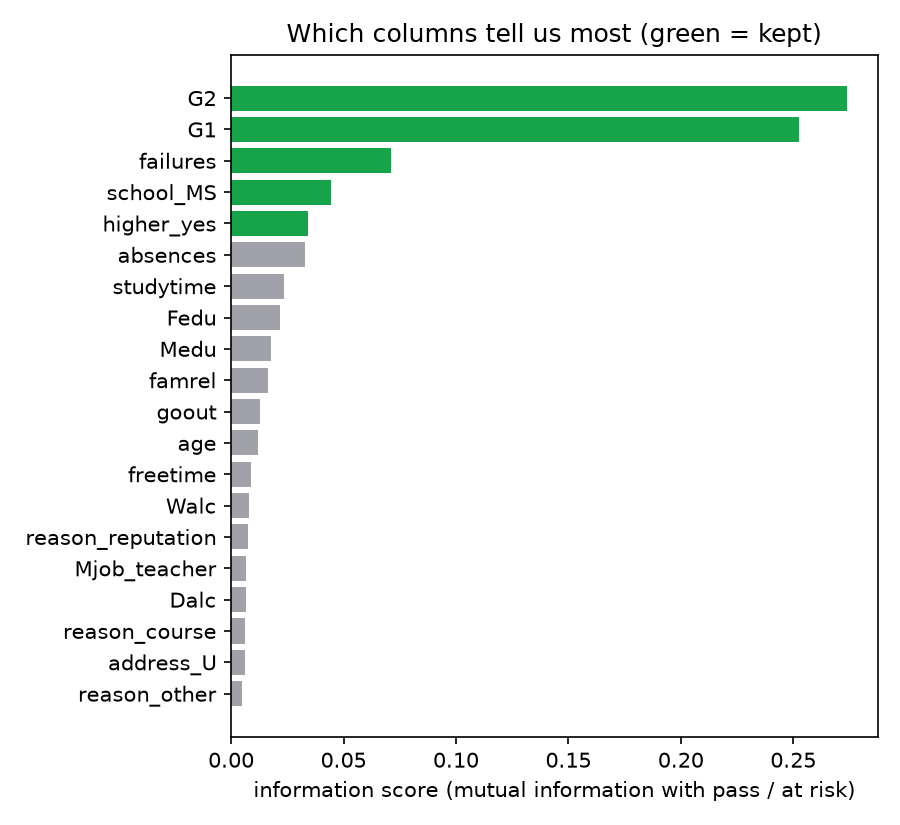

address
rural    0.213
urban    0.127
Name: at_risk, dtype: float64 



address,rural at-risk rate,urban at-risk rate
G2,,
G2 <= 8,0.92,0.91
G2 = 9,0.36,0.29
G2 = 10,0.15,0.10
G2 >= 11,0.00,0.00


In [13]:
display(Image("results/figures/feature_scores.png", width=560))
# Example: address. Rural students fail more often, but they also have lower grades.
print(train.groupby("address").at_risk.mean().rename({"R": "rural", "U": "urban"}).round(3), "\n")
band = pd.cut(train.G2, [-1, 8, 9, 10, 20], labels=["G2 <= 8", "G2 = 9", "G2 = 10", "G2 >= 11"])
display(train.pivot_table(index=band, columns="address", values="at_risk", aggfunc="mean", observed=True)
        .rename(columns={"R": "rural at-risk rate", "U": "urban at-risk rate"}).round(2))

**Address example.** Overall, rural students fail more often (21% vs 13%). But among students with the **same G2 grade**, rural and urban students fail at about the same rate.
So once we know the grades, address adds almost nothing new. That is why its information score is low and it was not kept.
The same reasoning applies to the other unused inputs; the app's "Feature choices" tab gives a reason for each one.

## 12. Predicting individual students (what the app does)

In [14]:
sample = pd.concat([test[test.at_risk == 1].head(3), test[test.at_risk == 0].head(3)])
out = sample[["G1", "G2", "failures", "higher", "school", "G3"]].copy()
out["chance of failing"] = predict_at_risk(net, prep.transform(sample)).round(3)
out["prediction"] = np.where(out["chance of failing"] >= 0.5, "AT RISK", "PASS")
out["actual"] = np.where(sample.at_risk == 1, "AT RISK", "PASS")
out

,G1,G2,failures,higher,school,G3,chance of failing,prediction,actual
256,7,8,1,no,GP,8,0.743,AT RISK,AT RISK
168,7,8,0,yes,GP,8,0.670,AT RISK,AT RISK
646,11,12,0,yes,MS,9,0.000,PASS,AT RISK
21,11,12,0,yes,GP,12,0.000,PASS,PASS
208,13,12,0,yes,GP,12,0.000,PASS,PASS
278,9,12,0,yes,GP,13,0.010,PASS,PASS


## 13. Summary

| Question | Answer |
|---|---|
| Data | UCI Student Performance, Portuguese course, 649 students, 32 inputs |
| Target | PASS (G3 ≥ 10) or AT RISK (G3 < 10) |
| Inputs used | Top 5 by information score: G2, G1, past failures, school, wants higher education |
| Model | Keras neural network: 5 inputs → 16 → 8 → 1, ReLU, dropout 0.4, sigmoid output |
| Training | Adam (learning rate 0.01), binary cross-entropy, batches of 32, early stopping |
| Choices | Number of inputs, layer sizes, dropout, learning rate, activation and optimizer, all chosen by 5-fold cross-validation |
| Result | 93.1% test accuracy; best cross-validation F1 and recall of all models |
| Comparison | Logistic regression 92.3%, decision tree 93.8%, random forest 90.0%, always-pass 84.6% (test accuracy) |

**Limitations**
- **Small data:** 649 students from 2 schools in one year.
- **Missed students:** the model misses 1 in 4 failing students.
- **Grades only:** it relies mainly on the period grades, so it predicts well only after the 1st and 2nd grading periods.